# 01 · Máscaras automáticas (hoja vs. fondo)

Para entrenar la UNet necesitamos, para cada foto, una **máscara**: una imagen en blanco
y negro del mismo tamaño, con **blanco donde está la hoja** y **negro en el fondo**.
El dataset no trae máscaras, y dibujar más de 2000 a mano es inviable.

**El truco:** la hoja tiene colores intensos (verde, amarillo, marrón) y el fondo suele ser
blanco o gris, o sea, colores "apagados". Esa intensidad del color se llama **saturación**.
Separando lo saturado de lo apagado obtenemos una máscara aproximada, sin red neuronal.

Estas máscaras no son perfectas: por eso después las **revisamos** y descartamos las malas.

Este notebook corre en la compu (no necesita GPU).

In [1]:
import shutil

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import utils

utils.set_estilo()
df = utils.cargar_splits()          # 2393 fotos (sin duplicados), con su split
print(len(df), 'fotos')

2393 fotos


## 1. Exploración del dataset
Cuántas fotos hay de cada clase y en cada parte (train / val / test).

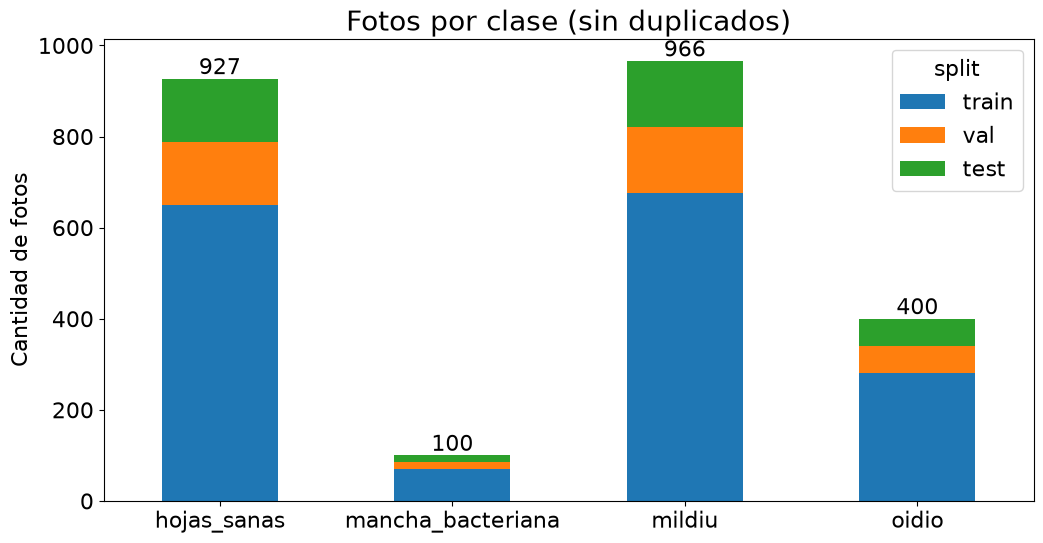

split,train,val,test
clase,,,
hojas_sanas,649,139,139
mancha_bacteriana,70,15,15
mildiu,676,145,145
oidio,280,60,60


In [2]:
tabla = pd.crosstab(df['clase'], df['split'])[['train', 'val', 'test']]
fig, ax = plt.subplots(figsize=(12, 6))
tabla.plot.bar(stacked=True, ax=ax, rot=0)
ax.set_title('Fotos por clase (sin duplicados)')
ax.set_xlabel('')
ax.set_ylabel('Cantidad de fotos')
for i, total in enumerate(tabla.sum(axis=1)):
    ax.text(i, total + 10, str(total), ha='center', fontsize=16)
utils.guardar_figura(fig, 'distribucion_clases')
plt.show()
tabla

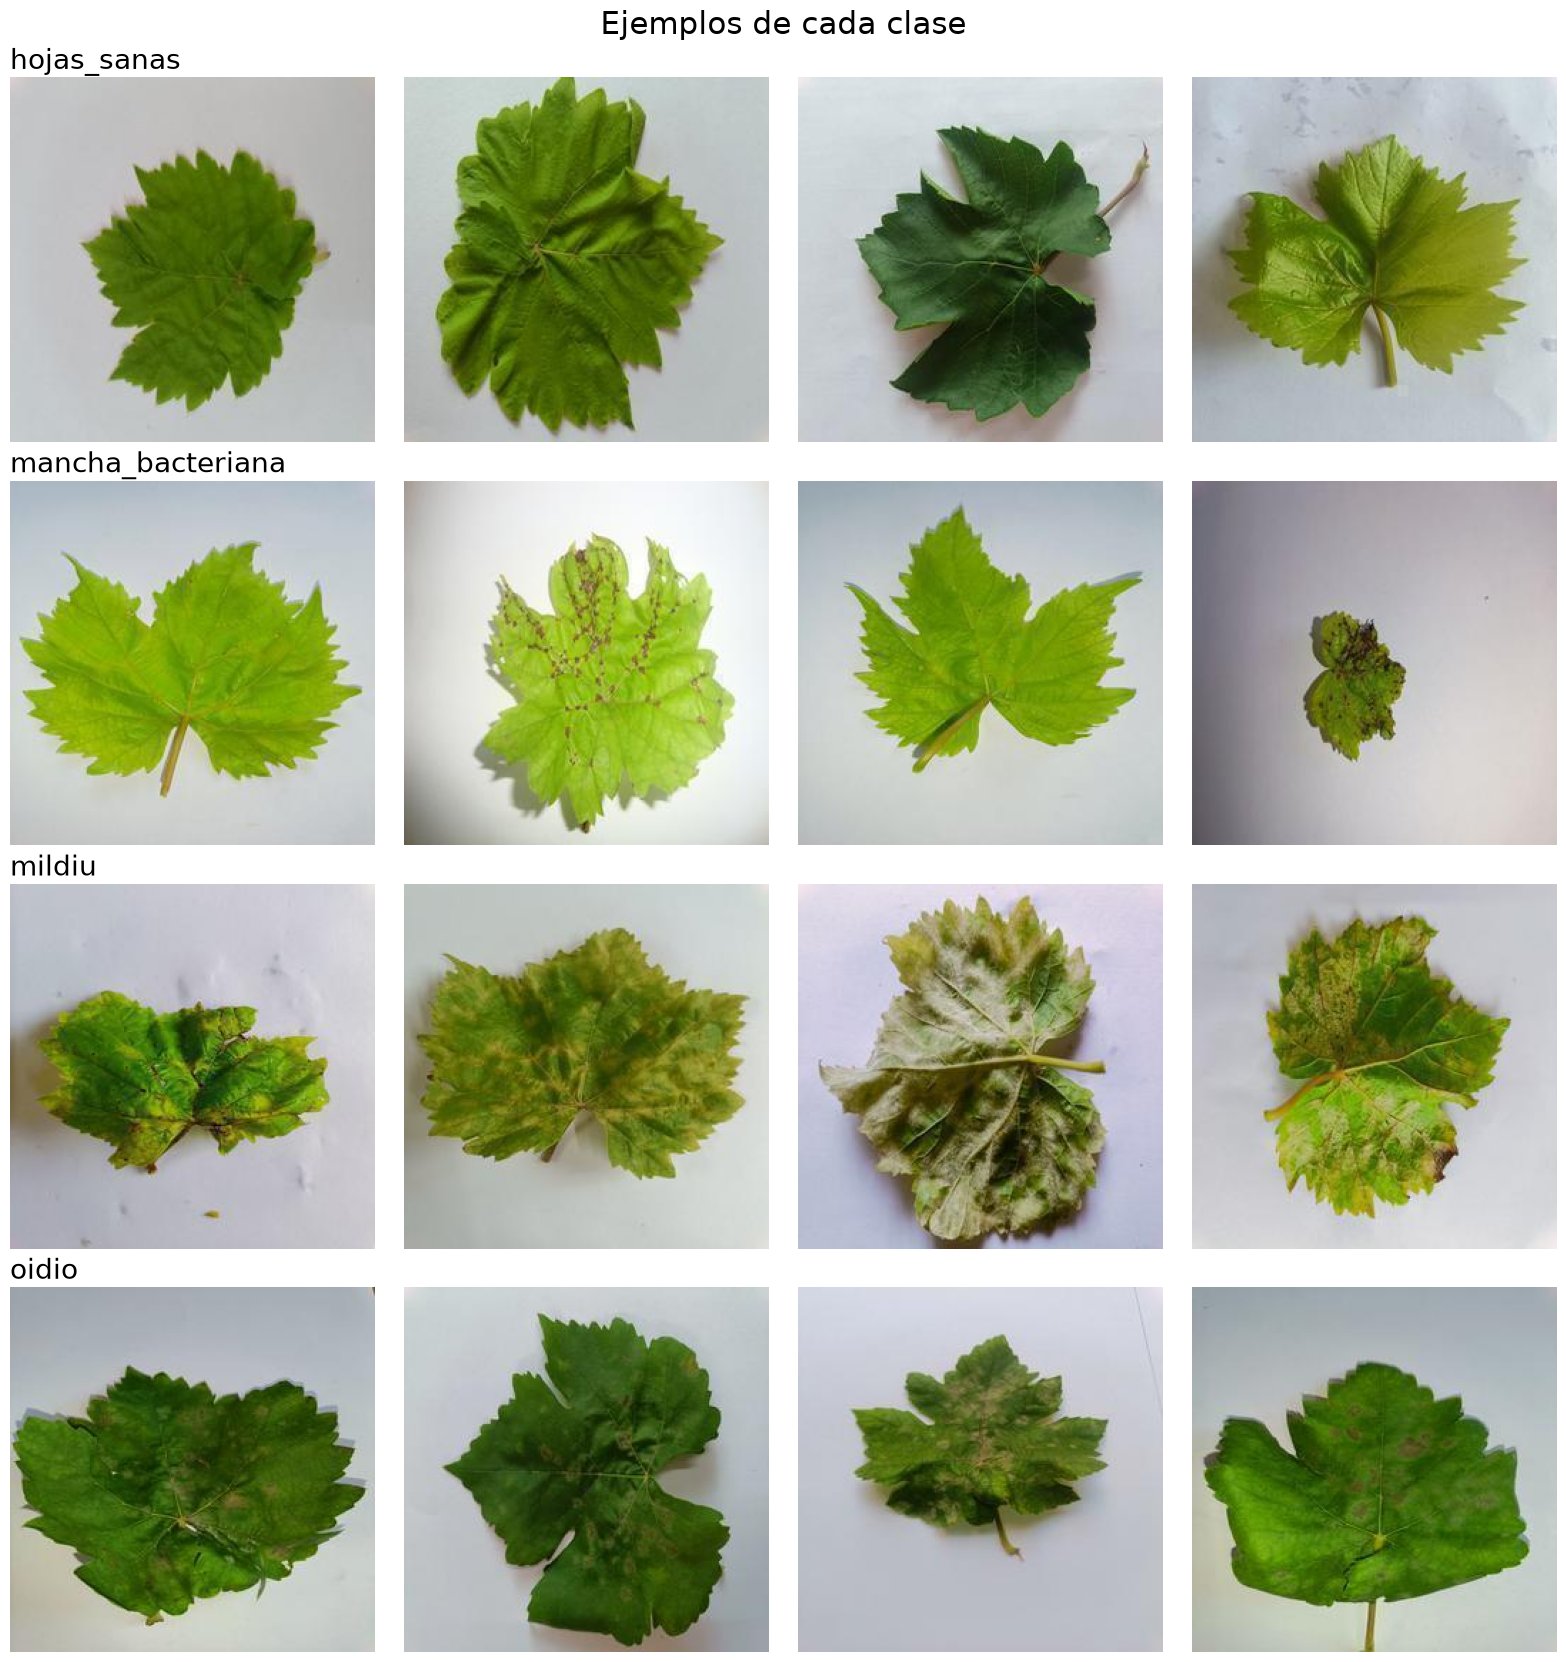

In [3]:
fig, ax = plt.subplots(4, 4, figsize=(16, 17))
for fila, clase in enumerate(utils.CLASES):
    ejemplos = df[df['clase'] == clase].sample(4, random_state=utils.SEED)
    for col, path in enumerate(ejemplos['path']):
        ax[fila, col].imshow(utils.cargar_imagen(path))
        ax[fila, col].axis('off')
    ax[fila, 0].set_title(clase, loc='left')
fig.suptitle('Ejemplos de cada clase')
fig.tight_layout()
utils.guardar_figura(fig, 'ejemplos_clases')
plt.show()

## 2. La máscara paso a paso
La función `utils.mascara_auto()` hace 6 pasos. Los mostramos sobre una foto:

1. **Canal S (saturación):** pasamos la foto de RGB a **HSV** (tono, saturación, brillo) y nos
   quedamos con la saturación. La hoja se ve clara y el fondo oscuro.
2. **Umbral de Otsu:** convierte la imagen a blanco o negro. El método de Otsu elige solo el
   mejor punto de corte entre "claro" y "oscuro".
3. **Apertura + cierre:** limpieza con un "pincel" circular. La apertura borra puntitos blancos
   sueltos del fondo y el cierre tapa agujeritos negros dentro de la hoja.
4. **Mancha más grande:** si quedaron varias manchas blancas, nos quedamos con la más grande: la hoja.
5. **Rellenar huecos:** algunas lesiones (marrones, poco saturadas) quedan como agujeros dentro de
   la hoja. Pintamos el fondo desde afuera; lo que quedó sin pintar es un hueco, y lo rellenamos.

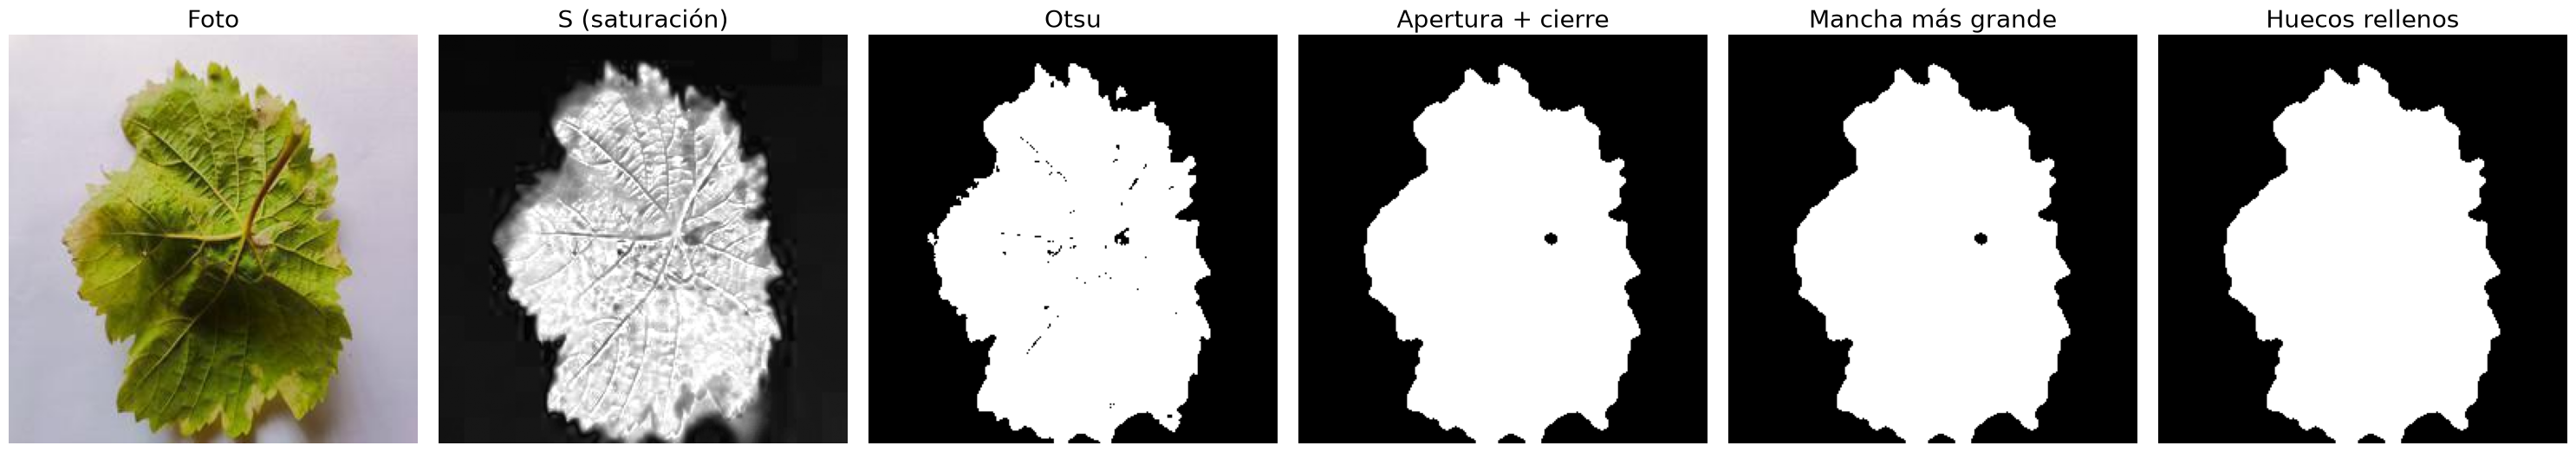

In [4]:
# Una hoja de mildiu con lesiones y fondo visible
path = df[df['clase'] == 'mildiu'].sample(4, random_state=1)['path'].iloc[1]
img = utils.cargar_imagen(path)
mascara, pasos = utils.mascara_auto(img, pasos=True)

fig, ax = plt.subplots(1, 6, figsize=(30, 6))
ax[0].imshow(img)
ax[0].set_title('Foto')
for a, (nombre, imagen) in zip(ax[1:], pasos.items()):
    a.imshow(imagen, cmap='gray')
    a.set_title(nombre)
for a in ax:
    a.axis('off')
fig.tight_layout()
utils.guardar_figura(fig, 'mascara_pasos')
plt.show()

### ¿Por qué la saturación y no otro canal?
Los tres canales de HSV de la misma foto. En **H (tono)** el fondo y la hoja se mezclan, y las
lesiones marrones tienen otro tono que el verde. En **V (brillo)** el fondo blanco es lo más claro.
En **S** la hoja entera (con sus lesiones) se separa mejor del fondo.

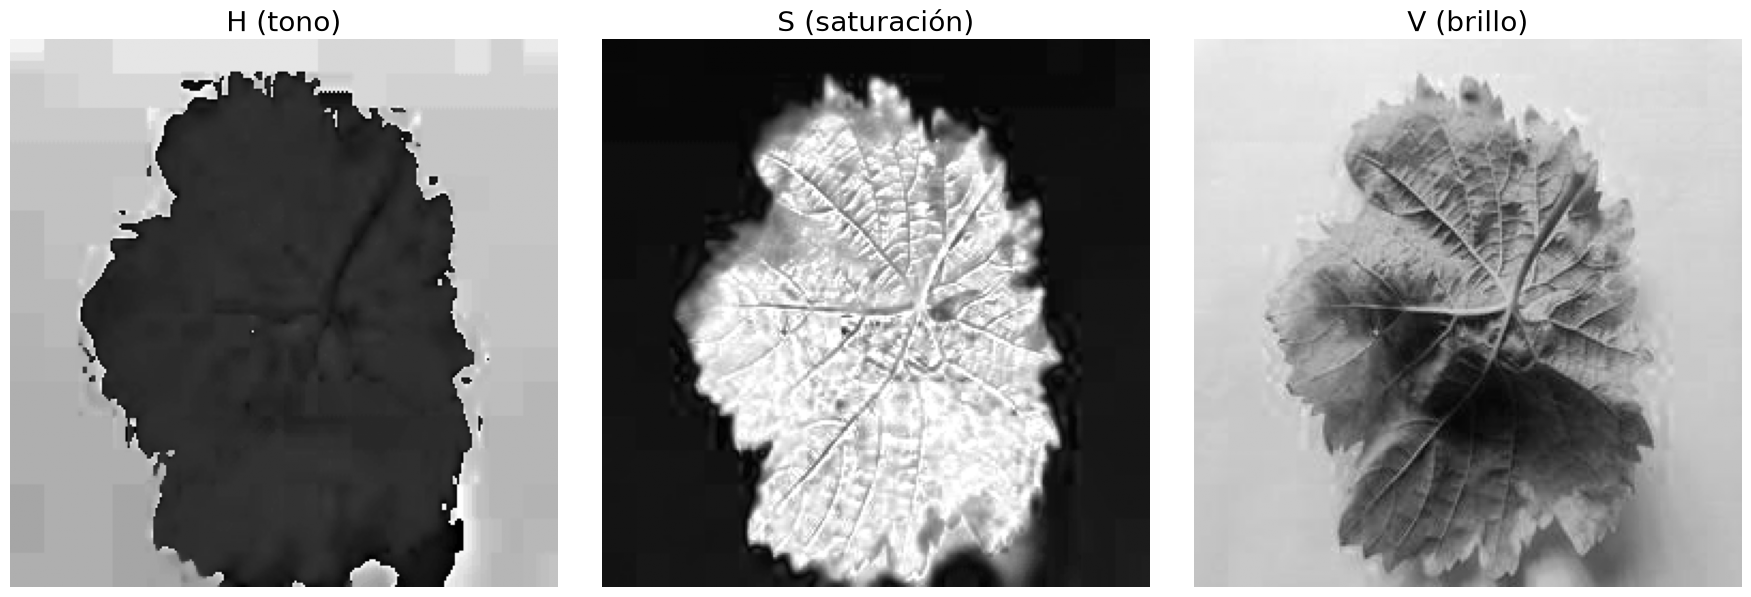

In [5]:
hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for i, nombre in enumerate(['H (tono)', 'S (saturación)', 'V (brillo)']):
    ax[i].imshow(hsv[:, :, i], cmap='gray')
    ax[i].set_title(nombre)
    ax[i].axis('off')
fig.tight_layout()
utils.guardar_figura(fig, 'canales_hsv')
plt.show()

## 3. Ejemplos de varias clases
En rojo, el contorno de la máscara sobre la foto. Arriba de cada foto, qué parte de la imagen
ocupa la hoja.

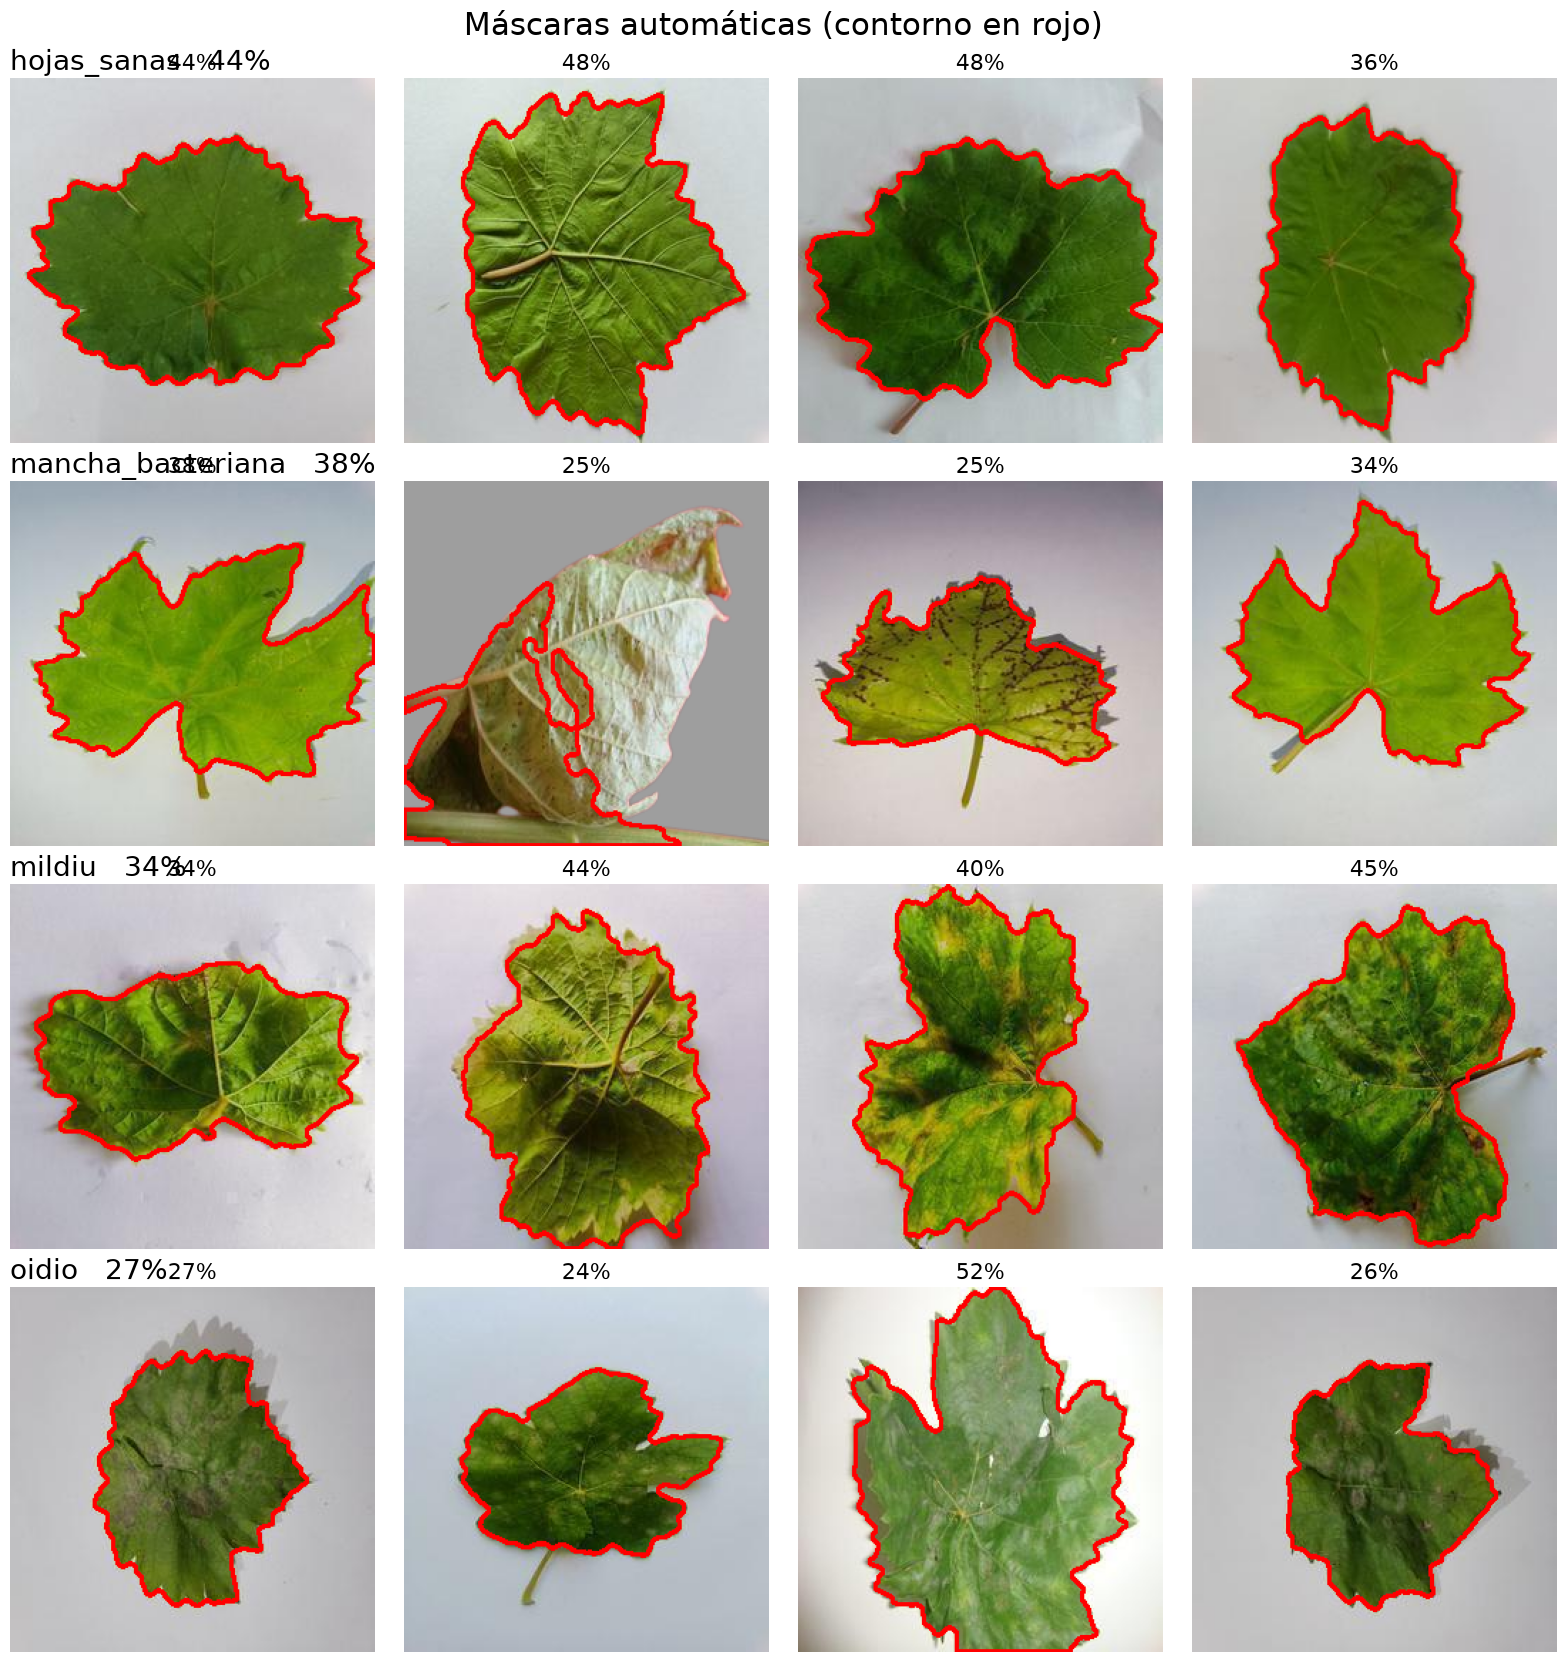

In [6]:
def dibujar_contorno(img, mascara):
    salida = img.copy()
    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(salida, contornos, -1, (255, 0, 0), 2)
    return salida


fig, ax = plt.subplots(4, 4, figsize=(16, 17))
for fila, clase in enumerate(utils.CLASES):
    ejemplos = df[df['clase'] == clase].sample(4, random_state=1)
    for col, path in enumerate(ejemplos['path']):
        img = utils.cargar_imagen(path)
        m = utils.mascara_auto(img)
        ax[fila, col].imshow(dibujar_contorno(img, m))
        ax[fila, col].set_title(f'{np.mean(m > 0):.0%}', fontsize=16)
        ax[fila, col].axis('off')
    ax[fila, 0].set_title(f'{clase}   {ax[fila, 0].get_title()}', loc='left')
fig.suptitle('Máscaras automáticas (contorno en rojo)')
fig.tight_layout()
utils.guardar_figura(fig, 'mascaras_ejemplos')
plt.show()

## 4. Generar las máscaras de todas las fotos
Se guardan en `masks/auto/<clase>/<nombre>.png` (0 = fondo, 255 = hoja). **No se toca `dataset/`.**

Además marcamos como **sospechosas** las máscaras que ocupan menos del 2% o más del 95% de la
foto: casi seguro salieron mal.

In [7]:
carpeta_auto = utils.ROOT / 'masks' / 'auto'
areas, sospechosas = [], []

for path in df['path']:
    img = utils.cargar_imagen(path)
    m = utils.mascara_auto(img)
    destino = carpeta_auto / path.split('/')[1] / (path.split('/')[-1].rsplit('.', 1)[0] + '.png')
    destino.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(destino), m)
    areas.append(np.mean(m > 0))
    if utils.es_sospechosa(m):
        sospechosas.append(path)

df['area_mascara'] = areas
df['mascara'] = [
    'masks/auto/' + p.split('/')[1] + '/' + p.split('/')[-1].rsplit('.', 1)[0] + '.png'
    for p in df['path']
]
print('Máscaras generadas:', len(df))
print('Sospechosas:', len(sospechosas))

Máscaras generadas: 2393
Sospechosas: 1


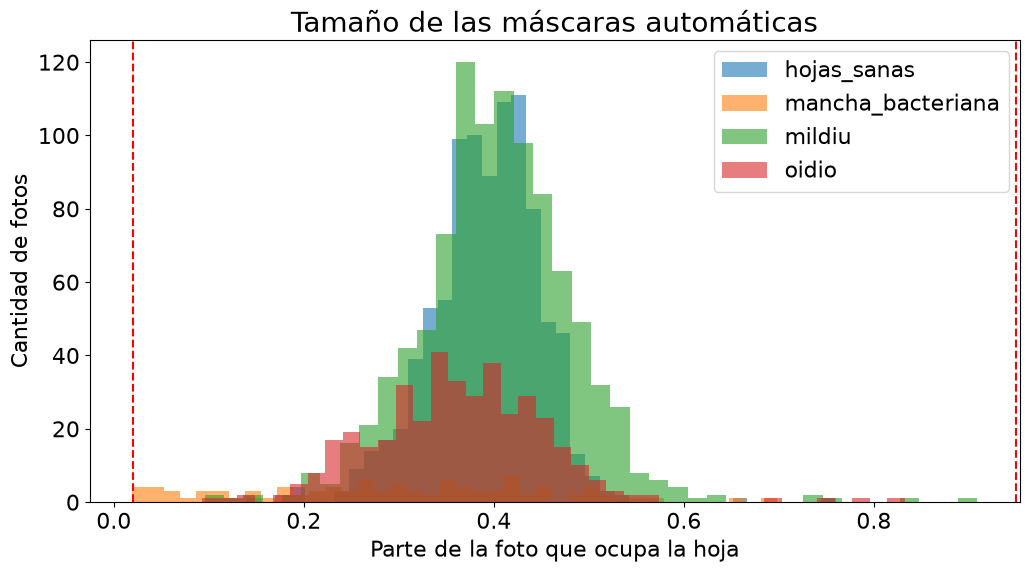

In [8]:
fig, ax = plt.subplots(figsize=(12, 6))
for clase in utils.CLASES:
    ax.hist(df.loc[df['clase'] == clase, 'area_mascara'], bins=40, alpha=0.6, label=clase)
ax.axvline(0.02, color='red', linestyle='--')
ax.axvline(0.95, color='red', linestyle='--')
ax.set_xlabel('Parte de la foto que ocupa la hoja')
ax.set_ylabel('Cantidad de fotos')
ax.set_title('Tamaño de las máscaras automáticas')
ax.legend()
utils.guardar_figura(fig, 'area_mascaras')
plt.show()

La lista de máscaras malas va en `masks/rechazadas.txt` (una ruta por línea). La primera vez se
crea con las sospechosas; **después la completan ustedes** al revisar las grillas. Si el archivo
ya existe, no se pisa.

In [9]:
ruta_rechazadas = utils.ROOT / 'masks' / 'rechazadas.txt'
if ruta_rechazadas.exists():
    print('rechazadas.txt ya existe: no se modifica.')
else:
    ruta_rechazadas.write_text(''.join(p + '\n' for p in sospechosas), encoding='utf-8')
    print('rechazadas.txt creado con', len(sospechosas), 'sospechosas')

rechazadas.txt ya existe: no se modifica.


## 5. Grillas para revisar a ojo
Guardamos todas las fotos con su contorno en grillas de 24, en `figuras/revision_mascaras/`.
Cada foto tiene su **nombre de archivo** arriba: si una máscara está mal, se copia su ruta
(`dataset/<clase>/<nombre>`) en `masks/rechazadas.txt`.

In [10]:
carpeta_rev = utils.ROOT / 'figuras' / 'revision_mascaras'
carpeta_rev.mkdir(parents=True, exist_ok=True)
POR_GRILLA = 24

for clase in utils.CLASES:
    filas = df[df['clase'] == clase].reset_index(drop=True)
    for n, inicio in enumerate(range(0, len(filas), POR_GRILLA)):
        grupo = filas.iloc[inicio:inicio + POR_GRILLA]
        fig, ax = plt.subplots(4, 6, figsize=(24, 17))
        for a in ax.flat:
            a.axis('off')
        for a, (_, fila) in zip(ax.flat, grupo.iterrows()):
            img = utils.cargar_imagen(fila['path'])
            m = cv2.imread(str(utils.ROOT / fila['mascara']), cv2.IMREAD_GRAYSCALE)
            a.imshow(dibujar_contorno(img, m))
            a.set_title(fila['path'].split('/')[-1], fontsize=12)
        fig.suptitle(f'{clase}  ·  grilla {n + 1}')
        fig.tight_layout()
        fig.savefig(carpeta_rev / f'{clase}_{n + 1:03d}.png', dpi=80)
        plt.close(fig)

print('Grillas guardadas en', carpeta_rev)

Grillas guardadas en C:\Users\enzos\OneDrive\Desktop\Archivos\Facultad\Inteligencia Artificial\Proyecto Final\figuras\revision_mascaras


## 6. Elegir 50 fotos de test para corregir a mano
Para medir qué tan bien segmenta la UNet hacen falta máscaras **correctas**, no automáticas.
Elegimos 50 fotos del split **test** (12 o 13 por clase, empezando por las sospechosas) y copiamos
su máscara automática a `masks/manual/` como punto de partida para corregirlas.

Si una máscara ya está en `masks/manual/`, no se pisa (puede estar corregida).

In [11]:
carpeta_manual = utils.ROOT / 'masks' / 'manual'
cupo = {'hojas_sanas': 13, 'mancha_bacteriana': 12, 'mildiu': 13, 'oidio': 12}
test = df[df['split'] == 'test'].copy()
test['sospechosa'] = test['path'].isin(sospechosas)

elegidas = []
for clase, n in cupo.items():
    t = test[test['clase'] == clase]
    t = pd.concat([t[t['sospechosa']],
                   t[~t['sospechosa']].sample(frac=1, random_state=utils.SEED)])
    elegidas.append(t.head(n))
elegidas = pd.concat(elegidas)

for _, fila in elegidas.iterrows():
    destino = carpeta_manual / fila['mascara'].removeprefix('masks/auto/')
    destino.parent.mkdir(parents=True, exist_ok=True)
    if not destino.exists():
        shutil.copy(utils.ROOT / fila['mascara'], destino)

(carpeta_manual / 'LISTA.txt').write_text(
    ''.join(p + '\n' for p in elegidas['path']), encoding='utf-8')
print(len(elegidas), 'fotos elegidas')
elegidas['clase'].value_counts()

50 fotos elegidas


clase
hojas_sanas          13
mildiu               13
mancha_bacteriana    12
oidio                12
Name: count, dtype: int64

## Lo que sigue (lo hacen ustedes)
1. **Revisar las grillas** de `figuras/revision_mascaras/` y agregar las rutas de las máscaras malas
   a `masks/rechazadas.txt`. Esas fotos no se usan para entrenar la UNet.
2. **Corregir a mano** las 50 máscaras de `masks/manual/` (blanco = hoja, negro = fondo), por
   ejemplo con GIMP. La lista está en `masks/manual/LISTA.txt`.